# Intro

In [2]:
import pandas as pd

df = pd.read_csv("Depot_sales.csv", header=0, parse_dates=["date"], index_col="date")
cut = int(len(df) * 2/3)

df_fit = df.iloc[:cut] #4 years of the series
df_test = df.iloc[cut:] #2 years of the series (years 5 and 6)



print(df["Product_A"])
#print(df_test)

date
2020-01-01    43.0
2020-01-02    41.0
2020-01-03    43.0
2020-01-04    43.0
2020-01-05    41.0
              ... 
2025-12-27    46.0
2025-12-28    49.0
2025-12-29    46.0
2025-12-30    46.0
2025-12-31    45.0
Name: Product_A, Length: 2192, dtype: float64


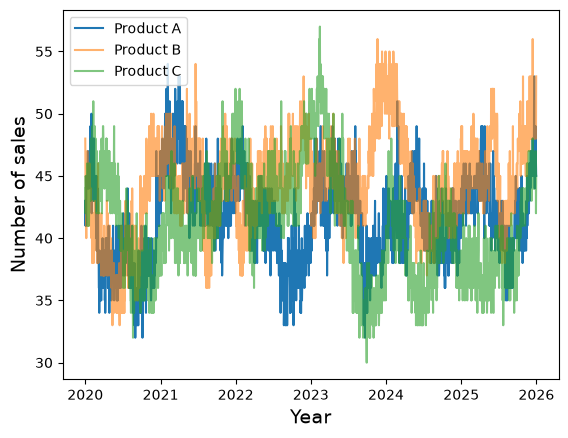

In [5]:
from matplotlib import pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots()
ax.plot(df.index, df["Product_A"], label="Product A")
ax.plot(df.index, df["Product_B"], label ="Product B",alpha = 0.6)
ax.plot(df.index, df["Product_C"], label="Product C", alpha= 0.6)
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()



In [ ]:
import numpy as np

yearly_means = (
    df.groupby(df.index.year)[["Product_A", "Product_B", "Product_C"]]
    .mean()
    .rename_axis("Year")
    .round(2)
)
yearly_means

,Product_A,Product_B,Product_C
Year,,,
2020,38.83,40.63,40.80
2021,44.52,44.44,42.22
2022,40.20,44.69,44.20
2023,41.81,45.50,41.47
2024,41.33,44.55,38.89
2025,42.45,45.69,38.94


### Performing a simple linear regression fit using generalised least squares to predict future price behaviour.

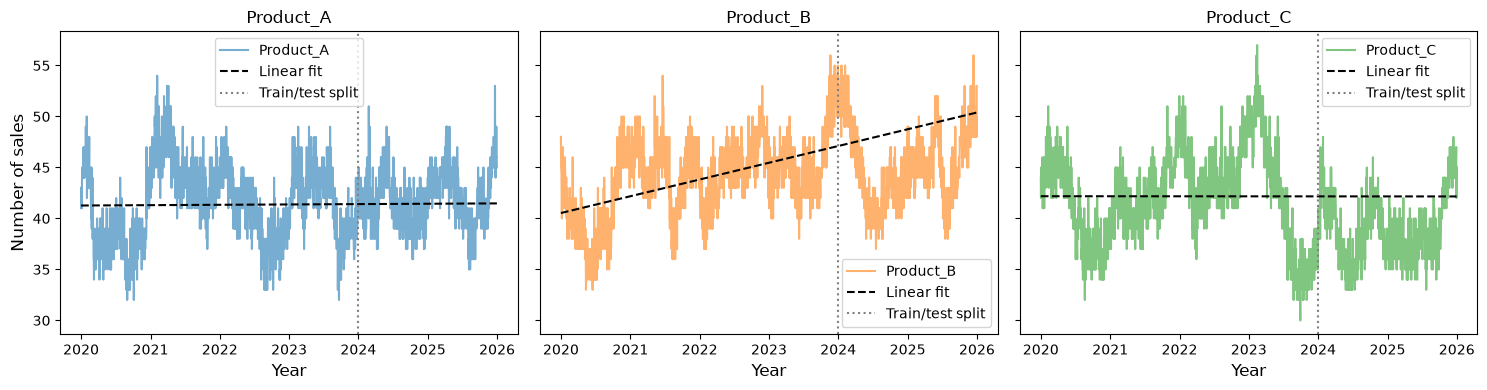

,Product,Method,RMSE train,RMSE test
0,Product_A,OLS,3.85,2.80
1,Product_B,OLS,3.29,5.24
2,Product_C,OLS,4.55,4.54


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from sklearn.metrics import root_mean_squared_error 


products = ["Product_A", "Product_B", "Product_C"]
colours = {"Product_A": "tab:blue", "Product_B": "tab:orange", "Product_C": "tab:green"}

# Time as days since the start of the series
t0 = df.index[0]
days_all = (df.index - t0).days.to_numpy()
days_fit = (df_fit.index - t0).days.to_numpy()
days_test = (df_test.index - t0).days.to_numpy()

results = []  # shared scoreboard: later models append rows in the same format
    
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, p in zip(axes, products):
    y_fit = df_fit[p].to_numpy()
    y_test = df_test[p].to_numpy()
    # Fit on the training period only, then predict across the whole series
    fit = stats.linregress(days_fit, df_fit[p])
    predict = lambda d: fit.intercept + fit.slope * d
    #predict = fit.intercept + fit.slope * days_all

    rmse_train = root_mean_squared_error(y_fit, predict(days_fit))
    rmse_test = root_mean_squared_error(y_test, predict(days_test))
    
    training_results = {"Product": p, "Method": "OLS", "RMSE train": rmse_train, "RMSE test": rmse_test}
    results.append(training_results)

    ax.plot(df.index, df[p], color=colours[p], alpha=0.6, label=p)
    ax.plot(df.index, predict(days_all), color="black", linestyle="--", label="Linear fit")
    ax.axvline(df_test.index[0], color="grey", linestyle=":", label="Train/test split")

    ax.set_title(p)
    ax.set_xlabel("Year", fontsize=12)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.legend()

axes[0].set_ylabel("Number of sales", fontsize=12)
plt.tight_layout()
plt.show()

pd.DataFrame(results).round(2)


### The linear fits do give good results for mean (based off the regression fit) and low p-values but due to correaltion as it is a time series and visually it clearly is missing a significant amount of the behaviour of the curve, though they are cheap to calculate.

### Using a non-linear curve fit instead

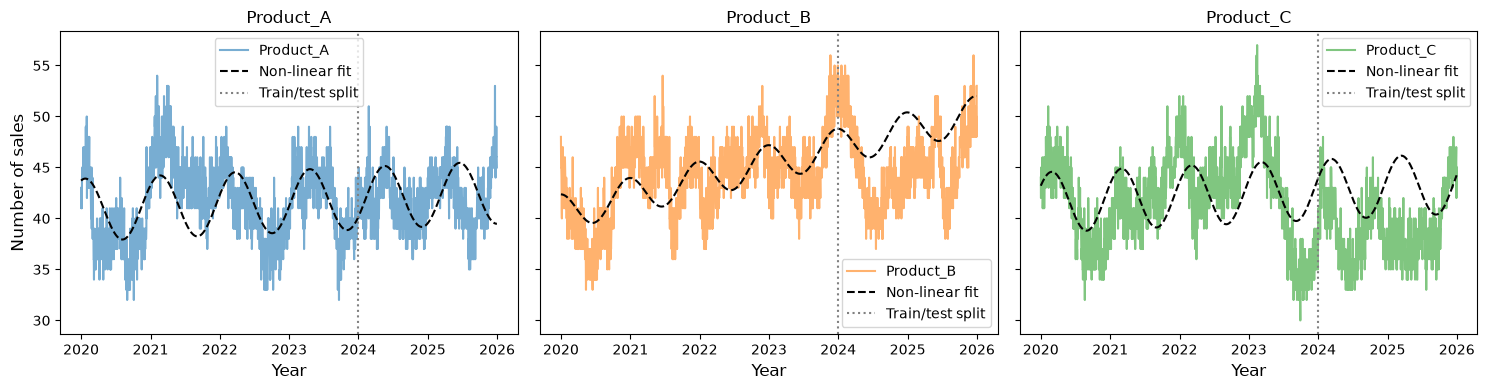

,Product,Method,RMSE train,RMSE test
0,Product_A,OLS,3.85,2.80
3,Product_A,Harmonic regression,3.16,3.43
4,Product_B,Harmonic regression,3.04,4.92
1,Product_B,OLS,3.29,5.24
2,Product_C,OLS,4.55,4.54
5,Product_C,Harmonic regression,4.06,5.68


In [28]:
from scipy.optimize import curve_fit

def seasonal_trend(x, a, c, w, trend, const):
    return a * np.sin(w * x) + c * np.cos(w * x) + trend * x + const

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, p in zip(axes, products):
    y_fit = df_fit[p].to_numpy()
    y_test = df_test[p].to_numpy()

    # Starting guesses: annual cycle, no trend, centred on the training mean
    p0 = [y_fit.std(), y_fit.std(), 2 * np.pi / 365.25, 0.0, y_fit.mean()]

    # Fit on training data
    params, _ = curve_fit(seasonal_trend, days_fit, y_fit, p0=p0, method="trf", maxfev=20000)
    predict = lambda d: seasonal_trend(d, *params)
    #print(params)

    # fitting_period = np.round(2 * np.pi / abs(params[2], 2))
    # print("fitted period is ", fitting_period, " days")

    rmse_train = root_mean_squared_error(y_fit, predict(days_fit))
    rmse_test = root_mean_squared_error(y_test, predict(days_test))

    results.append({"Product": p, "Method": "Harmonic regression", "RMSE train": rmse_train, "RMSE test": rmse_test})

    ax.plot(df.index, df[p], color=colours[p], alpha=0.6, label=p)
    ax.plot(df.index, predict(days_all), color="black", linestyle="--", label="Non-linear fit")
    ax.axvline(df_test.index[0], color="grey", linestyle=":", label="Train/test split")

    ax.set_title(p)
    ax.set_xlabel("Year", fontsize=12)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.legend()

axes[0].set_ylabel("Number of sales", fontsize=12)
plt.tight_layout()
plt.show()

pd.DataFrame(results).sort_values(["Product", "RMSE test"]).round(2)

### Kernel ridge regression

Product_A: best kernel ridge params {'alpha': 10, 'gamma': 5}
Product_B: best kernel ridge params {'alpha': 0.1, 'gamma': 100}
Product_C: best kernel ridge params {'alpha': 10, 'gamma': 5}


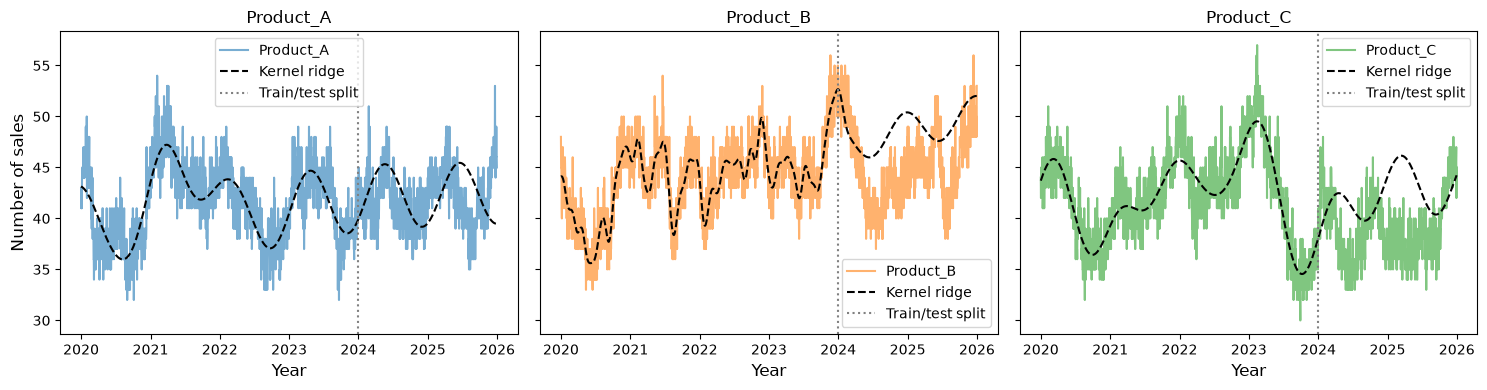

,Product,Method,RMSE train,RMSE test
0,Product_A,OLS,3.85,2.80
1,Product_B,OLS,3.29,5.24
2,Product_C,OLS,4.55,4.54
3,Product_A,Harmonic regression,3.16,3.43
4,Product_B,Harmonic regression,3.04,4.92
5,Product_C,Harmonic regression,4.06,5.68
6,Product_A,Harmonic + kernel ridge,2.31,3.45
7,Product_B,Harmonic + kernel ridge,1.67,4.87
8,Product_C,Harmonic + kernel ridge,2.13,5.20


In [ ]:
from sklearn.kernel_ridge import KernelRidge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# Kernel ridge works on time measured in years
years_all = (days_all / 365.25).reshape(-1, 1)
years_fit = (days_fit / 365.25).reshape(-1, 1)

param_grid = {"alpha": [0.01, 0.1, 1, 10], "gamma": [1, 5, 20, 50, 100]}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, p in zip(axes, products):
    y_fit = df_fit[p].to_numpy()
    y_test = df_test[p].to_numpy()

    #Parametric fit on the training period (as in the trig cell)
    p0 = [y_fit.std(), y_fit.std(), 2 * np.pi / 365.25, 0.0, y_fit.mean()]
    params, _ = curve_fit(seasonal_trend, days_fit, y_fit, p0=p0, method="trf", maxfev=20000)
    trig = lambda d: seasonal_trend(d, *params)

    #Kernel ridge fit on the training residuals
    resid_fit = y_fit - trig(days_fit)
    grid = GridSearchCV(
        KernelRidge(kernel="rbf"),
        param_grid=param_grid,
        cv=TimeSeriesSplit(n_splits=5),
        scoring="neg_root_mean_squared_error",
    )
    grid.fit(years_fit, resid_fit)
    krr = grid.best_estimator_
    print(f"{p}: best kernel ridge params {grid.best_params_}")

    #Combining both fits
    predict = lambda d: trig(d) + krr.predict((d / 365.25).reshape(-1, 1))

    rmse_train = root_mean_squared_error(y_fit, predict(days_fit))
    rmse_test = root_mean_squared_error(y_test, predict(days_test))

    results.append({"Product": p, "Method": "Harmonic + kernel ridge", "RMSE train": rmse_train, "RMSE test": rmse_test})

    ax.plot(df.index, df[p], color=colours[p], alpha=0.6, label=p)
    ax.plot(df.index, predict(days_all), color="black", linestyle="--", label="Kernel ridge")
    ax.axvline(df_test.index[0], color="grey", linestyle=":", label="Train/test split")

    ax.set_title(p)
    ax.set_xlabel("Year", fontsize=12)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.legend()

axes[0].set_ylabel("Number of sales", fontsize=12)
plt.tight_layout()
plt.show()

pd.DataFrame(results).round(2)

### Holt-Winters exponential curve smoothing used to statistical model the time series

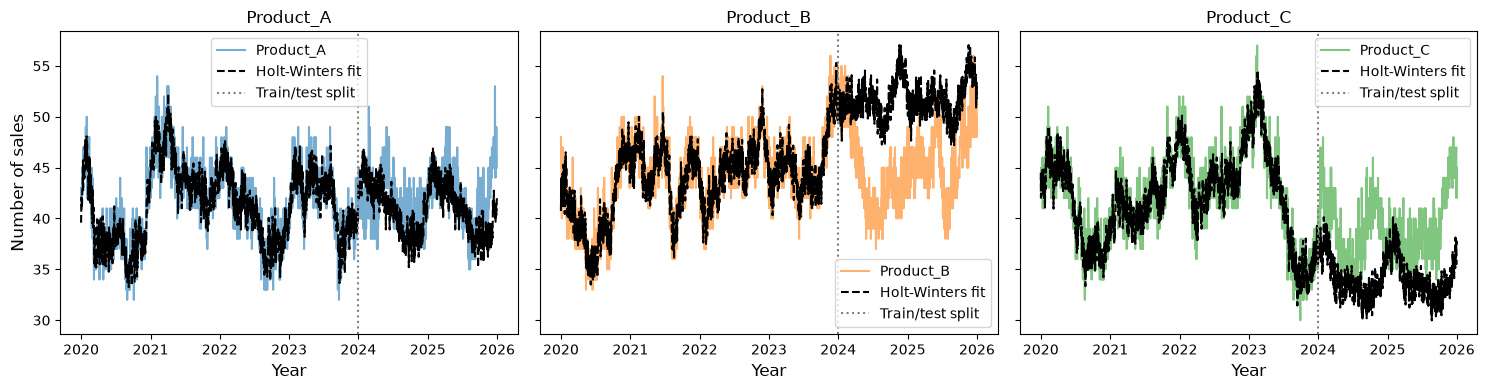

,Product,Method,RMSE train,RMSE test
0,Product_A,OLS,3.85,2.80
9,Product_A,Holt-Winters,1.72,3.09
3,Product_A,Harmonic regression,3.16,3.43
6,Product_A,Harmonic + kernel ridge,2.31,3.45
7,Product_B,Harmonic + kernel ridge,1.67,4.87
4,Product_B,Harmonic regression,3.04,4.92
1,Product_B,OLS,3.29,5.24
10,Product_B,Holt-Winters,1.65,7.55
2,Product_C,OLS,4.55,4.54
8,Product_C,Harmonic + kernel ridge,2.13,5.20


In [30]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, p in zip(axes, products):
    y_fit = df_fit[p].to_numpy()
    y_test = df_test[p].to_numpy()

    # Holt-Winters needs a regular daily index with no gaps
    train_daily = df_fit[p].asfreq("D")
    if train_daily.isna().any():
        print(f"{p}: {train_daily.isna().sum()} missing days interpolated")
        train_daily = train_daily.interpolate()

    # Fit on the training period only
    hw = ExponentialSmoothing(
        train_daily,
        trend="add",
        damped_trend=True,                  # stops the trend extrapolating forever
        seasonal="add",
        seasonal_periods=365,
        initialization_method="heuristic",).fit()

    # In-sample fitted values for the training dates
    fitted_train = hw.fittedvalues.reindex(df_fit.index).to_numpy()

    # Out-of-sample forecast, from the end of training to the last test date
    horizon = (df_test.index[-1] - train_daily.index[-1]).days
    forecast = hw.forecast(horizon).reindex(df_test.index).to_numpy()

    rmse_train = root_mean_squared_error(y_fit, fitted_train)
    rmse_test = root_mean_squared_error(y_test, forecast)

    results.append({"Product": p, "Method": "Holt-Winters",
                    "RMSE train": rmse_train, "RMSE test": rmse_test})

    ax.plot(df.index, df[p], color=colours[p], alpha=0.6, label=p)
    ax.plot(df_fit.index, fitted_train, color="black", linestyle="--", label="Holt-Winters fit")
    ax.plot(df_test.index, forecast, color="black", linestyle="--")
    ax.axvline(df_test.index[0], color="grey", linestyle=":", label="Train/test split")

    ax.set_title(p)
    ax.set_xlabel("Year", fontsize=12)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.legend()

axes[0].set_ylabel("Number of sales", fontsize=12)
plt.tight_layout()
plt.show()

pd.DataFrame(results).sort_values(["Product", "RMSE test"]).round(2)

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error

def check_stationarity(timeseries):
    result = adfuller(timeseries, autolag='AIC')
    p_value = result[1]
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {p_value}')
    print('Stationary' if p_value < 0.05 else 'Non-Stationary')


check_stationarity(df["Product_A"])

ADF Statistic: -3.5250169159284166
p-value: 0.007367376282928845
Stationary


C:\Users\joe\AppData\Local\Temp\ipykernel_22940\288555616.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(timeseries, autolag='AIC')


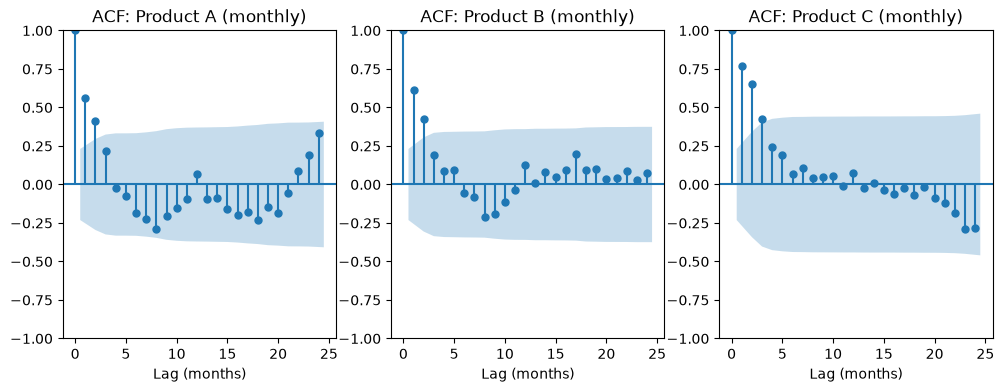

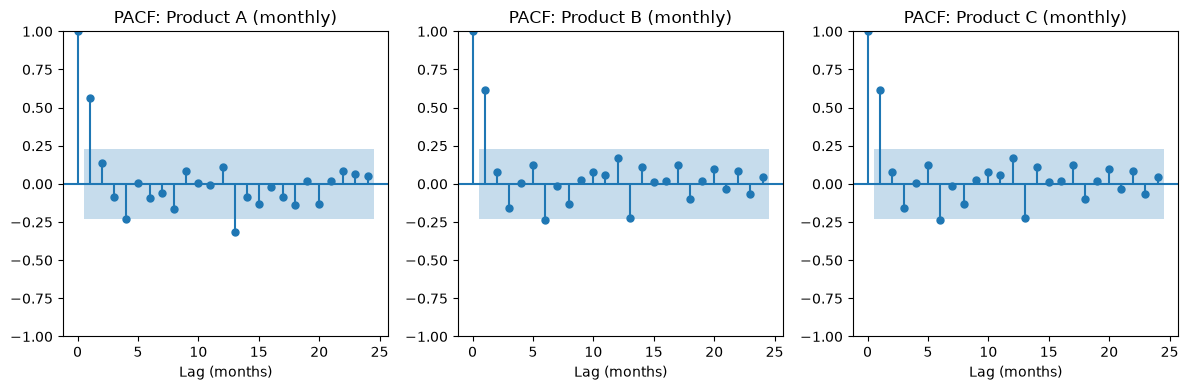

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error

monthly_sales_A = df["Product_A"].resample('ME').sum()
monthly_sales_B = df["Product_B"].resample('ME').sum()
monthly_sales_C = df["Product_C"].resample('ME').sum()
#monthly_sales.head()

fig_1, axes_1 = plt.subplots(1, 3, figsize=(12, 4))

plot_acf(monthly_sales_A, lags=24, ax=axes_1[0])
plot_acf(monthly_sales_B, lags=24, ax=axes_1[1])
plot_acf(monthly_sales_C, lags=24, ax=axes_1[2])

fig_2, axes_2 = plt.subplots(1, 3, figsize=(12, 4))
plot_pacf(monthly_sales_A, lags=24, ax=axes_2[0], method="ywm")
plot_pacf(monthly_sales_B, lags=24, ax=axes_2[1], method="ywm")
plot_pacf(monthly_sales_B, lags=24, ax=axes_2[2], method="ywm")

axes_1[0].set_title("ACF: Product A (monthly)")
axes_1[1].set_title("ACF: Product B (monthly)")
axes_1[2].set_title("ACF: Product C (monthly)")
axes_2[0].set_title("PACF: Product A (monthly)")
axes_2[1].set_title("PACF: Product B (monthly)")
axes_2[2].set_title("PACF: Product C (monthly)")
axes_1[0].set_xlabel("Lag (months)")
axes_1[1].set_xlabel("Lag (months)")
axes_1[2].set_xlabel("Lag (months)")
axes_2[0].set_xlabel("Lag (months)")
axes_2[1].set_xlabel("Lag (months)")
axes_2[2].set_xlabel("Lag (months)")
plt.tight_layout()
plt.show()

c:\Users\joe\miniconda3\envs\data\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\joe\miniconda3\envs\data\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\joe\miniconda3\envs\data\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


ValueError: x and y must have same first dimension, but have shapes (2192,) and (12,)

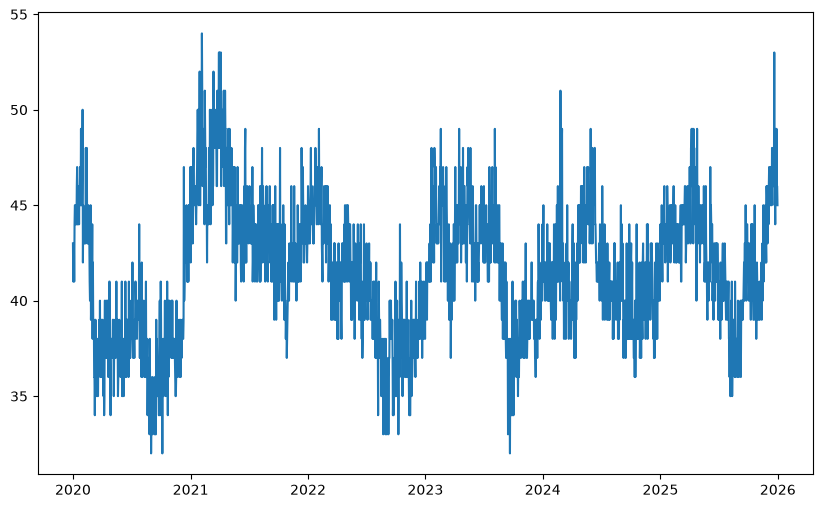

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import root_mean_squared_error 

monthly = df["Product_A"].resample("MS").mean()
m_fit = monthly[monthly.index < df_test.index[0]]
m_test = monthly[monthly.index >= df_test.index[0]]
series_len= len(df.index)

#First go
p, d, q = 2, 1, 3
P, D, Q, s = 1, 1, 0, 12

model = SARIMAX(df_fit["Product_A"], order=(p, d, q), seasonal_order=(P, D, Q, s))
sarima = model.fit()
print(sarima)
      
forecast_periods = 12
forecast = sarima.forecast(steps=forecast_periods)

# rmse_train = root_mean_squared_error(A_fit, results)
# rmse_test = root_mean_squared_error(A_test, forecast)

plt.figure(figsize=(10, 6))
plt.plot(df["Product_A"], label='Observed')
plt.plot(forecast, label='Forecast', color='black')
plt.title("Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.show()

# print(rmse_train)
# print(rmse_test)

In [5]:
len(forecast)

12

AIC 156.8
RMSE train 2.02 | test 3.66


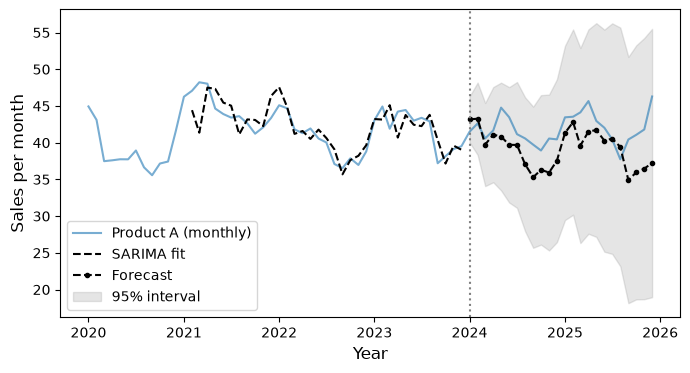

In [9]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import matplotlib.dates as mdates

monthly = df["Product_A"].resample("MS").mean()
m_fit = monthly[monthly.index < df_test.index[0]]
m_test = monthly[monthly.index >= df_test.index[0]]

order, seasonal_order = (2, 1, 3), (1, 1, 0, 12)

sarima_fit = SARIMAX(m_fit, order=order, seasonal_order=seasonal_order).fit(disp=False)

# Forecast the whole test period, with a confidence interval
fc = sarima_fit.get_forecast(steps=len(m_test))
forecast = fc.predicted_mean
ci = fc.conf_int()

# In-sample fit, skipping the first d + D*s points (the model hasn't initialised yet)
skip = order[1] + seasonal_order[1] * seasonal_order[3]
fitted = sarima_fit.fittedvalues.iloc[skip:]

print(f"AIC {sarima_fit.aic:.1f}")
print(f"RMSE train {root_mean_squared_error(m_fit.iloc[skip:], fitted):.2f} | "
      f"test {root_mean_squared_error(m_test, forecast):.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(monthly.index, monthly, color="tab:blue", alpha=0.6, label="Product A (monthly)")
ax.plot(fitted.index, fitted, color="black", linestyle="--", label="SARIMA fit")
ax.plot(forecast.index, forecast, color="black", linestyle="--", marker="o", markersize=3, label="Forecast")
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="grey", alpha=0.2, label="95% interval")
ax.axvline(m_test.index[0], color="grey", linestyle=":")
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Sales per month", fontsize=12)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend()
plt.show()

In [10]:
print(m_fit)

date
2020-01-01    44.935484
2020-02-01    43.103448
2020-03-01    37.483871
2020-04-01    37.600000
2020-05-01    37.741935
2020-06-01    37.733333
2020-07-01    38.935484
2020-08-01    36.645161
2020-09-01    35.566667
2020-10-01    37.161290
2020-11-01    37.433333
2020-12-01    41.612903
2021-01-01    46.258065
2021-02-01    47.071429
2021-03-01    48.225806
2021-04-01    48.033333
2021-05-01    44.645161
2021-06-01    43.900000
2021-07-01    43.419355
2021-08-01    43.612903
2021-09-01    42.633333
2021-10-01    41.225806
2021-11-01    42.100000
2021-12-01    43.354839
2022-01-01    45.096774
2022-02-01    44.678571
2022-03-01    41.806452
2022-04-01    41.300000
2022-05-01    41.935484
2022-06-01    40.566667
2022-07-01    40.032258
2022-08-01    37.096774
2022-09-01    36.533333
2022-10-01    37.870968
2022-11-01    36.966667
2022-12-01    38.806452
2023-01-01    43.032258
2023-02-01    44.928571
2023-03-01    41.903226
2023-04-01    44.233333
2023-05-01    44.451613
2023-06-01 